In [3]:
package CoffeeMachineRequirements {

    package DCE {
        requirement <'FR-01'> telemetryCollection {
            doc /*
            Платформа приймає телеметрію щонайменше
            від восьми сигналів кавомашини.
            */
        }

        requirement <'FR-05'> deviceControl {
            doc /*
            Платформа передає команди запуску,
            зупинки та зміни температурної уставки.
            */
        }

        requirement <'FR-07'> connectionMonitoring {
            doc /*
            Платформа визначає стани online та offline.
            */
        }

        requirement <'NFR-04'> deliveryReliability {
            doc /*
            Для MQTT QoS 1 частка втрачених повідомлень
            не перевищує 0.1 %.
            */
        }

        requirement <'NFR-05'> reconnectTime {
            doc /*
            Підключення відновлюється не пізніше
            ніж за 5 секунд після відновлення Broker.
            */
        }
    }

    package DTE {
        requirement <'FR-02'> twinSynchronization {
            doc /*
            Платформа оновлює стан цифрового двійника
            після отримання телеметрії.
            */
        }

        requirement <'FR-03'> telemetryHistory {
            doc /*
            Платформа зберігає історичну телеметрію
            з часовими мітками.
            */
        }

        requirement <'FR-04'> anomalyDetection {
            doc /*
            Платформа виявляє Clog,
            HeaterFailure та PumpFailure.
            */
        }

        requirement <'NFR-01'> synchronizationLatency {
            doc /*
            Затримка синхронізації не перевищує
            250 мс для 95 % оновлень.
            */
        }

        requirement <'NFR-03'> scalability {
            doc /*
            Збільшення кількості сигналів з 8 до 80
            збільшує p95 затримки не більш ніж на 30 %.
            */
        }

        requirement <'NFR-06'> throughput {
            doc /*
            Платформа обробляє щонайменше
            100 повідомлень за секунду.
            */
        }
    }

    package UE {
        requirement <'FR-06'> statePresentation {
            doc /*
            Платформа відображає стан, телеметрію
            та інформацію про аномалії.
            */
        }

        requirement <'NFR-02'> endToEndLatency {
            doc /*
            Наскрізна затримка датчик-подання
            не перевищує 500 мс для 95 % оновлень.
            */
        }
    }
}

Package CoffeeMachineRequirements (4ca95ba1-c3e8-4889-b519-ff75ce15c40c)


In [4]:
package CoffeeMachineStructure {

    part def DataCollection;
    part def DeviceControl;
    part def TwinStateManager;
    part def AnomalyAnalyzer;
    part def TelemetryRepository;
    part def ResourceAccess;
    part def TwinManagement;
    part def UserInterface;
    part def SecurityService;
    part def DataQualityService;
    part def InteroperabilityService;

    part def DigitalTwinPlatform {
        part dataCollection : DataCollection;
        part deviceControl : DeviceControl;

        part twinStateManager : TwinStateManager;
        part anomalyAnalyzer : AnomalyAnalyzer;
        part telemetryRepository : TelemetryRepository;

        part resourceAccess : ResourceAccess;
        part twinManagement : TwinManagement;
        part userInterface : UserInterface;

        part securityService : SecurityService;
        part dataQualityService : DataQualityService;
        part interoperabilityService : InteroperabilityService;
    }

    part platform : DigitalTwinPlatform;
}

Package CoffeeMachineStructure (2558a23a-89d5-4315-b943-e91425c507a6)


In [5]:
package CoffeeMachineConnections {

    port def TelemetryPort;
    port def CommandPort;
    port def StatePort;
    port def UserDataPort;

    part def DataCollection {
        port telemetryIn : TelemetryPort;
        port telemetryOut : TelemetryPort;
    }

    part def DataQualityService {
        port telemetryIn : TelemetryPort;
        port telemetryOut : TelemetryPort;
    }

    part def TwinStateManager {
        port telemetryIn : TelemetryPort;
        port stateOut : StatePort;
    }

    part def ResourceAccess {
        port stateIn : StatePort;
        port userDataOut : UserDataPort;
        port commandOut : CommandPort;
    }

    part def UserInterface {
        port userDataIn : UserDataPort;
        port commandOut : CommandPort;
    }

    part def DeviceControl {
        port commandIn : CommandPort;
    }

    part platform {

        part dataCollection : DataCollection;
        part dataQualityService : DataQualityService;
        part twinStateManager : TwinStateManager;
        part resourceAccess : ResourceAccess;
        part userInterface : UserInterface;
        part deviceControl : DeviceControl;

        connect dataCollection.telemetryOut
            to dataQualityService.telemetryIn;

        connect dataQualityService.telemetryOut
            to twinStateManager.telemetryIn;

        connect twinStateManager.stateOut
            to resourceAccess.stateIn;

        connect resourceAccess.userDataOut
            to userInterface.userDataIn;

        connect userInterface.commandOut
            to resourceAccess.commandOut;

        connect resourceAccess.commandOut
            to deviceControl.commandIn;
    }
}

Package CoffeeMachineConnections (8996cc5f-98b4-4a07-889c-4b764e062b96)


In [7]:
package CoffeeMachineBehavior {

    action def ProcessTelemetry {
        action receiveTelemetry;
        action validateTelemetry;
        action updateTwinState;
        action notifyUser;

        first receiveTelemetry then validateTelemetry;
        first validateTelemetry then updateTwinState;
        first updateTwinState then notifyUser;
    }

    action processTelemetry : ProcessTelemetry;
}

Package CoffeeMachineBehavior (55f217a3-008c-4420-a8e4-289556c341cd)


In [9]:
package CoffeeMachineTraceability {

    satisfy CoffeeMachineRequirements::DCE::telemetryCollection
        by CoffeeMachineStructure::platform.dataCollection;

    satisfy CoffeeMachineRequirements::DCE::deviceControl
        by CoffeeMachineStructure::platform.deviceControl;

    satisfy CoffeeMachineRequirements::DCE::connectionMonitoring
        by CoffeeMachineStructure::platform.twinManagement;

    satisfy CoffeeMachineRequirements::DCE::deliveryReliability
        by CoffeeMachineStructure::platform.dataCollection;

    satisfy CoffeeMachineRequirements::DCE::reconnectTime
        by CoffeeMachineStructure::platform.dataCollection;


    satisfy CoffeeMachineRequirements::DTE::twinSynchronization
        by CoffeeMachineStructure::platform.twinStateManager;

    satisfy CoffeeMachineRequirements::DTE::telemetryHistory
        by CoffeeMachineStructure::platform.telemetryRepository;

    satisfy CoffeeMachineRequirements::DTE::anomalyDetection
        by CoffeeMachineStructure::platform.anomalyAnalyzer;

    satisfy CoffeeMachineRequirements::DTE::synchronizationLatency
        by CoffeeMachineStructure::platform.twinStateManager;

    satisfy CoffeeMachineRequirements::DTE::scalability
        by CoffeeMachineStructure::platform;

    satisfy CoffeeMachineRequirements::DTE::throughput
        by CoffeeMachineStructure::platform;


    satisfy CoffeeMachineRequirements::UE::statePresentation
        by CoffeeMachineStructure::platform.userInterface;

    satisfy CoffeeMachineRequirements::UE::endToEndLatency
        by CoffeeMachineStructure::platform.resourceAccess;


    verification def VerifyFR01 {
        objective {
            verify CoffeeMachineRequirements::DCE::telemetryCollection;
        }
    }

    verification def VerifyFR02 {
        objective {
            verify CoffeeMachineRequirements::DTE::twinSynchronization;
        }
    }

    verification def VerifyFR03 {
        objective {
            verify CoffeeMachineRequirements::DTE::telemetryHistory;
        }
    }

    verification def VerifyFR04 {
        objective {
            verify CoffeeMachineRequirements::DTE::anomalyDetection;
        }
    }

    verification def VerifyFR05 {
        objective {
            verify CoffeeMachineRequirements::DCE::deviceControl;
        }
    }

    verification def VerifyFR06 {
        objective {
            verify CoffeeMachineRequirements::UE::statePresentation;
        }
    }

    verification def VerifyFR07 {
        objective {
            verify CoffeeMachineRequirements::DCE::connectionMonitoring;
        }
    }

    verification def VerifyNFR01 {
        objective {
            verify CoffeeMachineRequirements::DTE::synchronizationLatency;
        }
    }

    verification def VerifyNFR02 {
        objective {
            verify CoffeeMachineRequirements::UE::endToEndLatency;
        }
    }

    verification def VerifyNFR03 {
        objective {
            verify CoffeeMachineRequirements::DTE::scalability;
        }
    }

    verification def VerifyNFR04 {
        objective {
            verify CoffeeMachineRequirements::DCE::deliveryReliability;
        }
    }

    verification def VerifyNFR05 {
        objective {
            verify CoffeeMachineRequirements::DCE::reconnectTime;
        }
    }

    verification def VerifyNFR06 {
        objective {
            verify CoffeeMachineRequirements::DTE::throughput;
        }
    }
}

Package CoffeeMachineTraceability (4bb2a556-e3e8-4ecb-a5d9-c913ef699a06)


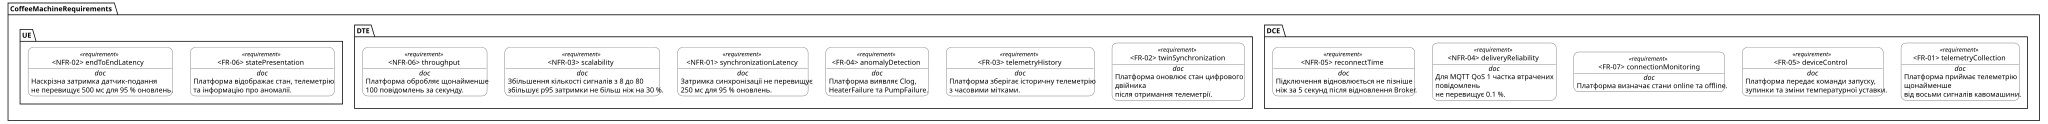

In [10]:
%viz --view=tree CoffeeMachineRequirements

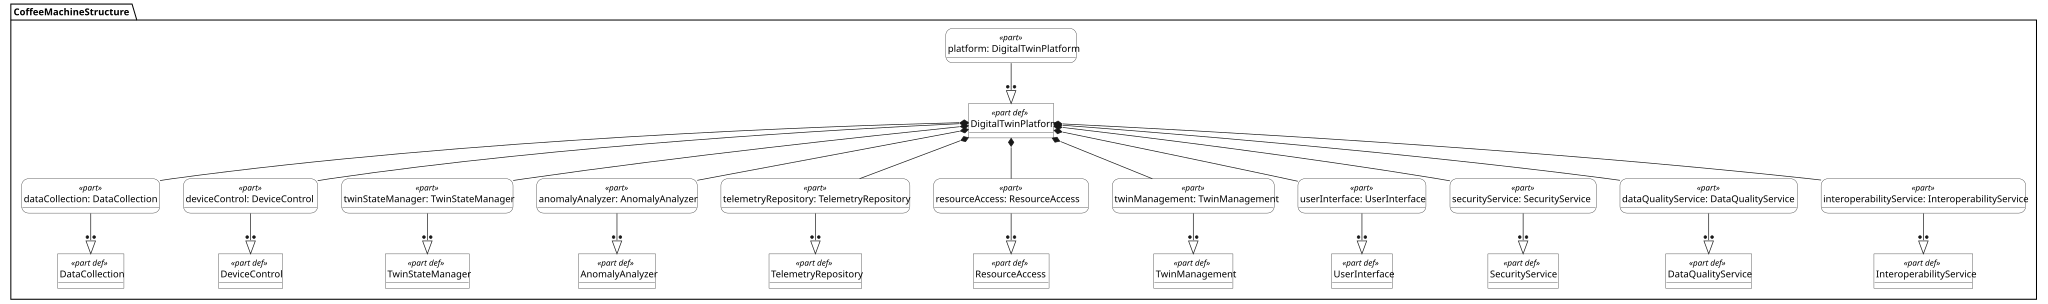

In [11]:
%viz --view=tree CoffeeMachineStructure

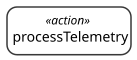

In [12]:
%viz --view=action CoffeeMachineBehavior::processTelemetry